# From inverted maps back to raw frames: the forward half of the ID03 exercise

You already have the inversion: `reduce_id03_scan.ipynb` Part C turns the 8 `obpitch` planes of the Mg-4Al g9 scan
into per-pixel tilt (mu, chi) and relative d-spacing maps. This notebook goes the other way and asks one question of
those maps:

> **Can the maps regenerate the raw frames, including frames of a plane they were not fitted on?**

It answers in two ways, side by side:

1. **An empirical forward model.** Each pixel is a separable Gaussian in (mu, chi, obpitch) built only from what the
   maps carry. Fast, transparent, scored against **held-out planes** with controls that can fail.
2. **The package's physical forward model.** The same maps become a one-voxel-thick deformation-gradient field, and
   `midas_dfxm`'s own goniometer rotations and reciprocal-space resolution function render the scan.

**What this is not.** One reflection, one layer, and the sample never translates. The maps are a 2-D projection with
depth unresolved. Nothing here is a 3-D microstructure, an elastic strain, or an absolute orientation. Section D says
what the result does and does not license. Every number in the cells is computed live; every number in the markdown
names the file it came from.

*Data:* `umich_school_raw_8planes.h5` (raw frames of all 8 planes, cropped to the grain box). Set `ID03_H5` or edit
`H5_PATH`. *Time:* a few minutes on a laptop (the file is read once). The cells run on a small ROI by design: the full
grain was run on a compute host, and its numbers are quoted in section B3.

In [1]:
import os
import h5py, hdf5plugin
import numpy as np
import matplotlib.pyplot as plt
import midas_dfxm as dx
import midas_dfxm.forward_maps as fm
import midas_dfxm.forward_thin_slab as ts

H5_PATH = os.environ.get("ID03_H5", "umich_school_raw_8planes.h5")
ROI = (300, 412, 1100, 1212)        # (row0, row1, col0, col1) in the file's crop; ~11,800 px, all inside the grain
with h5py.File(H5_PATH, "r") as f:
    LAM = float(f.attrs["wavelength_A"])
print("midas_dfxm", dx.__version__, "| wavelength", LAM, "A | ROI", ROI)

midas_dfxm 0.13.0 | wavelength 0.7293187971522731 A | ROI (300, 412, 1100, 1212)


## A. Load the ROI and look at the inversion

One pass over the file. Each plane is read, its **frame order is checked**, a per-frame pedestal (5th percentile) is
subtracted and, unlike the inversion's moments, the counts are **not clipped at zero**: a forward comparison has to be
scored on the same signed counts the detector recorded.

A plane far from the Bragg peak has almost no lit pixels in a small ROI, so the order check has no contrast to work
with and reports NOT CONFIRMED there. That says "nothing to test with", not "scrambled". The full-grain run required
and obtained CONSISTENT on all 8 planes.

plane 1.1: frame order NOT CONFIRMED (too few lit pixels in this ROI)
plane 2.1: frame order CONSISTENT
plane 3.1: frame order CONSISTENT
plane 4.1: frame order CONSISTENT
plane 5.1: frame order CONSISTENT
plane 6.1: frame order CONSISTENT
plane 7.1: frame order CONSISTENT
plane 8.1: frame order CONSISTENT
cube (mu, chi, obpitch, pixel) = (25, 26, 8, 11776); mu 20.173..21.133, chi -5.605..-4.605, obpitch 16.1191..16.2591 deg
primary (brightest) planes: ['5.1', '6.1', '4.1']


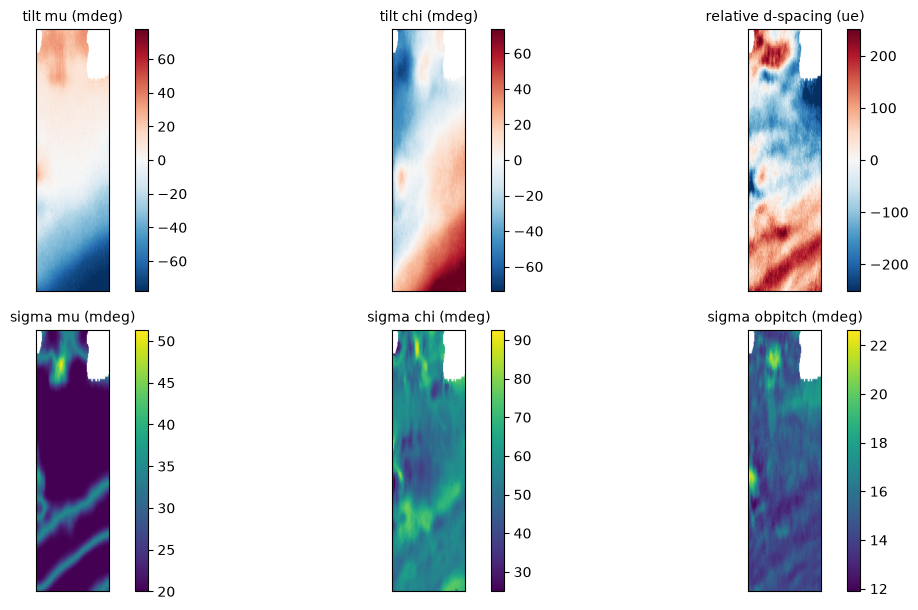

floored widths (fraction of pixels at half a motor step): {'mu': 0.561, 'chi': 0.0, 'ob': 0.0}


In [2]:
d = fm.load_planes_cube(H5_PATH, roi=ROI, require_consistent_order=False, log=lambda *a: None)
cube, mu_g, chi_g, ob_g, rc = d["cube"], d["mu_g"], d["chi_g"], d["ob_g"], d["rc"]
n_mu, n_chi, n_ob, P = cube.shape
H, W = d["union"].shape
for n, c in zip(d["planes"], d["order_checks"]):
    print(f"plane {n}: frame order", "CONSISTENT" if c.consistent else "NOT CONFIRMED (too few lit pixels in this ROI)")
print(f"cube (mu, chi, obpitch, pixel) = {cube.shape}; mu {mu_g[0]:.3f}..{mu_g[-1]:.3f}, chi {chi_g[0]:.3f}..{chi_g[-1]:.3f}, "
      f"obpitch {ob_g.min():.4f}..{ob_g.max():.4f} deg")

tot = [float(d["totals"][k][d["union"]].sum()) for k in range(n_ob)]
primary = [int(k) for k in np.argsort(tot)[::-1][:3]]      # the three brightest planes, chosen from the data alone
print("primary (brightest) planes:", [d["planes"][k] for k in primary])

def img(v, fill=np.nan):
    out = np.full((H, W), fill, float); out[rc[:, 0], rc[:, 1]] = v; return out

p_all = fm.fit_separable_params(cube, mu_g, chi_g, ob_g, list(range(n_ob)))
grain = d["union"][rc[:, 0], rc[:, 1]]
ob_ref = float(np.median(p_all.ob0)); th_ref = np.deg2rad(ob_ref) / 2
tilt_mu = 1e3 * (p_all.mu0 - np.median(p_all.mu0)); tilt_chi = 1e3 * (p_all.chi0 - np.median(p_all.chi0))
strain = -(np.deg2rad(p_all.ob0 - ob_ref) / 2) / np.tan(th_ref)
stretch = 1 / np.sin(2 * th_ref)                              # detector rows are foreshortened in the sample frame

fig, ax = plt.subplots(2, 3, figsize=(13, 6.2))
panels = [(tilt_mu, "tilt mu (mdeg)", "RdBu_r"), (tilt_chi, "tilt chi (mdeg)", "RdBu_r"), (1e6 * strain, "relative d-spacing (ue)", "RdBu_r"),
          (1e3 * p_all.smu, "sigma mu (mdeg)", "viridis"), (1e3 * p_all.schi, "sigma chi (mdeg)", "viridis"), (1e3 * p_all.sob, "sigma obpitch (mdeg)", "viridis")]
for a, (v, t, cm) in zip(ax.ravel(), panels):
    lim = np.nanpercentile(np.abs(v), 98) if cm == "RdBu_r" else None
    im = a.imshow(img(v), cmap=cm, aspect=stretch, **({"vmin": -lim, "vmax": lim} if lim else {}))
    a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([]); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()
print("floored widths (fraction of pixels at half a motor step):", {k: round(v, 3) for k, v in p_all.floored.items()})

The tilt maps are the baseline-removed centres of mass of the mu and chi marginals; the relative d-spacing map is the
obpitch centre turned into `delta d / d` (`-cot(theta) * d(2theta)/2`). The widths are the **half-maximum** widths of the
same marginals, per pixel. mu is sampled at about one point per FWHM, so the mu width sits at the floor (half a step) in
many pixels: it is the grain's own sampling, not a bug.

**Cross-check against what you already have.** The inversion in `reduce_id03_scan.ipynb` accumulates clipped marginals
with `accumulate_marginals`. Our centres come from unclipped counts. They should agree:

In [3]:
mu2, chi2, Mmu, Mchi, Mob = dx.accumulate_marginals(d["scans"])
ref_mu = dx.angular_moments(Mmu, mu2)["com"][rc[:, 0], rc[:, 1]]
ref_chi = dx.angular_moments(Mchi, chi2)["com"][rc[:, 0], rc[:, 1]]
for name, ours, ref in (("mu", p_all.mu0, ref_mu), ("chi", p_all.chi0, ref_chi)):
    print(f"{name}: correlation {np.corrcoef(ours[grain], ref[grain])[0, 1]:.4f}, "
          f"RMS difference {1e3 * np.sqrt(np.mean((ours - ref)[grain] ** 2)):.2f} mdeg "
          f"(a motor step is {1e3 * np.median(np.diff(mu_g)):.0f} mdeg)")

mu: correlation 1.0000, RMS difference 0.21 mdeg (a motor step is 40 mdeg)
chi: correlation 1.0000, RMS difference 0.25 mdeg (a motor step is 40 mdeg)


## B. The empirical forward model, scored on a plane it never saw

**Model.** For pixel `p`, plane `k`, frame `(mu_i, chi_j)`:

`y = b + A * g(ob_k; ob0, s_ob) * g(mu_i; mu0, s_mu) * g(chi_j; chi0, s_chi)`

with `g` a unit-peak Gaussian. Centres and widths come from the **seven planes that are not `k`**; `b` and `A` are a
one-parameter least squares on those seven planes' totals. Nothing from plane `k` enters. The grain mask is also
derived without plane `k`.

**Score.** Pooled within-pixel `R² = 1 - SSE/SST`, where SST is taken about each pixel's own mean over its 650 frames,
so pixel-to-pixel brightness cannot inflate it.

**Comparisons that can lose:** the same model with every pixel given the grain-median centres and widths (*uniform*: no
per-pixel orientation at all), and the previous-generation second-moment widths (*moment widths*). A pixel-shuffle null
and a width ablation follow.

In [4]:
masks = {k: d["fold_masks"][k][rc[:, 0], rc[:, 1]] for k in range(n_ob)}
variants = {
    "moment_widths": fm.moment_width_params,
    "uniform": fm.uniform_params,
    "abl_widths": lambda p, m: fm.ablate_params(p, m, ["smu", "schi", "sob"]),
    "abl_centres": lambda p, m: fm.ablate_params(p, m, ["mu0", "chi0", "ob0"]),
}
res = fm.leave_one_plane_out(cube, mu_g, chi_g, ob_g, primary, masks, variants, keep_params=True)
print(f"{'held-out plane':>16} " + " ".join(f"{v:>14}" for v in ["full", *variants]))
for k in primary:
    print(f"{d['planes'][k]:>16} " + " ".join(f"{res[k][v]['r2']:14.3f}" for v in ["full", *variants]))
pool = lambda v: 1 - sum(res[k][v]["sse"][masks[k]].sum() for k in primary) / sum(res[k][v]["sst"][masks[k]].sum() for k in primary)
print("pooled over the three:", {v: round(pool(v), 3) for v in ["full", *variants]})

  held-out plane           full  moment_widths        uniform     abl_widths    abl_centres
             5.1          0.635          0.222          0.358          0.621          0.405
             6.1          0.550          0.082          0.350          0.568          0.328
             4.1          0.661          0.093          0.251          0.702          0.298
pooled over the three: {'full': np.float64(0.623), 'moment_widths': np.float64(0.185), 'uniform': np.float64(0.347), 'abl_widths': np.float64(0.619), 'abl_centres': np.float64(0.381)}


Read the table as three questions. **full vs uniform**: do the per-pixel *centres and widths* carry information about
the frames of an unseen plane? **full vs abl_centres**: is it the centres? **full vs abl_widths**: do per-pixel
*widths* help, or only add noise? (At about one point per FWHM in mu they may add noise; the physical model below
makes exactly that choice, one width for the whole grain.)

Now the picture: held-out frames against the prediction, for the same settings.

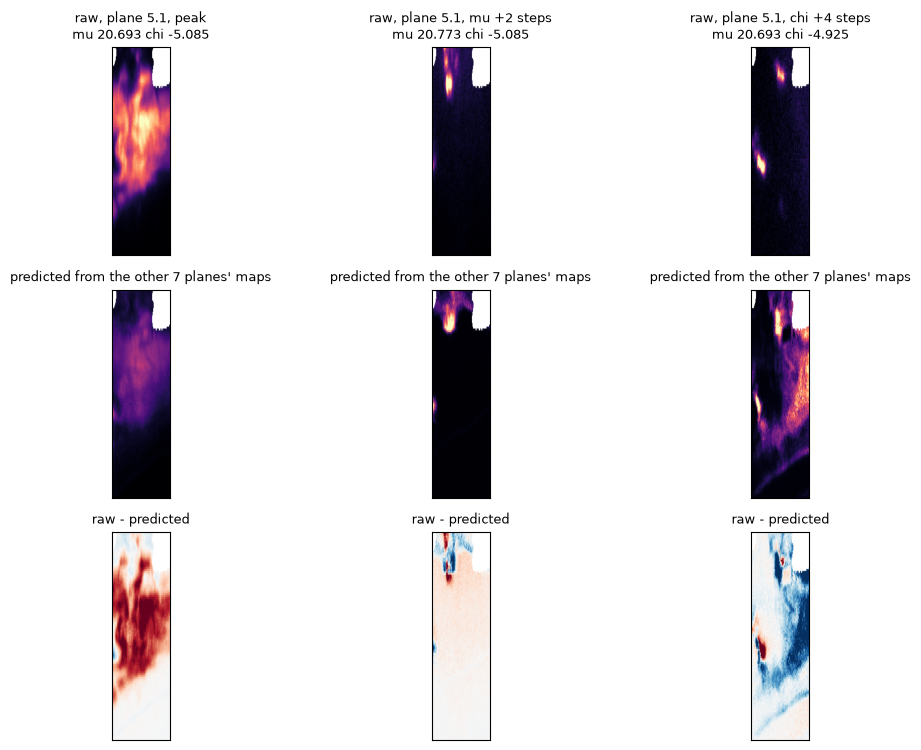

In [5]:
k0 = primary[0]
p0, m0 = res[k0]["_params"], masks[k0]
sse, sst, pred = fm.score_plane(cube[:, :, k0, :], p0, ob_g[k0], return_pred=True)
mean_curve = np.where(m0[None, None], cube[:, :, k0, :], 0).sum(2)
i_pk, j_pk = np.unravel_index(np.argmax(mean_curve), mean_curve.shape)
settings = [(i_pk, j_pk, "peak"), (min(i_pk + 2, n_mu - 1), j_pk, "mu +2 steps"), (i_pk, min(j_pk + 4, n_chi - 1), "chi +4 steps")]
fig, ax = plt.subplots(3, 3, figsize=(12, 7.6))
for c, (i, j, lab) in enumerate(settings):
    ra, pa = img(cube[i, j, k0, :]), img(pred[i, j, :])
    vmax = np.nanpercentile(ra, 99.5)
    ax[0, c].imshow(ra, cmap="magma", vmin=0, vmax=vmax, aspect=stretch); ax[0, c].set_title(f"raw, plane {d['planes'][k0]}, {lab}\nmu {mu_g[i]:.3f} chi {chi_g[j]:.3f}", fontsize=9)
    ax[1, c].imshow(pa, cmap="magma", vmin=0, vmax=vmax, aspect=stretch); ax[1, c].set_title("predicted from the other 7 planes' maps", fontsize=9)
    im = ax[2, c].imshow(ra - pa, cmap="RdBu_r", vmin=-vmax / 2, vmax=vmax / 2, aspect=stretch); ax[2, c].set_title("raw - predicted", fontsize=9)
    for r in range(3): ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
plt.tight_layout(); plt.show()

**Read the residual row, not just the score.** In this ROI the prediction for the held-out plane has the right *places*
lit (the structure follows the raw frame) but the wrong *amounts*: at the peak setting the bright core is under-predicted
(the Gaussian-in-obpitch interpolation misses the height of the held-out plane's peak), and at the chi flank the model
lights a region that the raw frame leaves dark (its half-max chi widths are too generous there). Those are the two
failure modes to look for whenever you change the ROI.

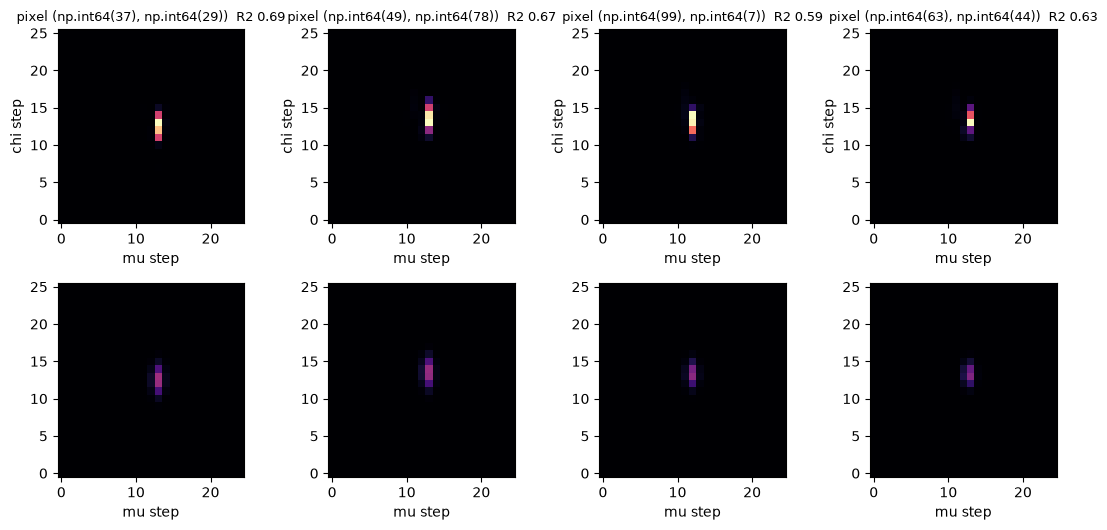

In [6]:
# Four pixels' own (mu, chi) rocking maps: raw (top) against prediction (bottom), the same colour scale.
rng = np.random.default_rng(0)
cand = np.flatnonzero(m0 & (sst > np.percentile(sst[m0], 60)))
pick = rng.choice(cand, 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(11, 5.4))
for c, q in enumerate(pick):
    vmax = cube[:, :, k0, q].max()
    ax[0, c].imshow(cube[:, :, k0, q].T, origin="lower", cmap="magma", vmin=0, vmax=vmax)
    ax[1, c].imshow(pred[:, :, q].T, origin="lower", cmap="magma", vmin=0, vmax=vmax)
    r2 = 1 - sse[q] / sst[q]
    ax[0, c].set_title(f"pixel {tuple(rc[q])}  R2 {r2:.2f}", fontsize=9); ax[0, c].set_xlabel("mu step"); ax[0, c].set_ylabel("chi step")
    ax[1, c].set_xlabel("mu step")
plt.tight_layout(); plt.show()

### B2. A control that can fail: shuffle the maps

If the score came from "this pixel is generally bright" or from the grain's average rocking curve, giving each pixel
**another pixel's** centres and widths would score about the same. It must not. (The registered run does this in 64 x 64
px blocks, because neighbouring pixels are correlated; here, on a small ROI, it is pixel by pixel, which is the harsher
choice for the model.)

In [7]:
idx = np.flatnonzero(m0)
sub = idx[:: max(1, len(idx) // 4000)]
nul = fm.permutation_null(cube[:, :, k0, :][:, :, sub], p0.take(sub), p0.take(idx), ob_g[k0],
                          lambda r: fm.pixel_donors(len(idx), r), 40, np.random.default_rng(1),
                          score_idx_in_pool=np.searchsorted(idx, sub))["r2"]
s_, t_ = fm.score_plane(cube[:, :, k0, :][:, :, sub], p0.take(sub), ob_g[k0])
print(f"plane {d['planes'][k0]}: observed R2 {fm.pooled_r2(s_, t_):.3f}; shuffled-maps null {nul.mean():.3f} +- {nul.std():.3f} "
      f"(max of {len(nul)}: {nul.max():.3f})")

plane 5.1: observed R2 0.635; shuffled-maps null 0.223 +- 0.004 (max of 40: 0.231)


### B3. The same test on the whole grain

**The registered full-grain run** (`examples/id03_forward_loo/PREREGISTER.md`, run by `run_forward_loo.py` in that folder, output
`results.json` there; 785,778 grain pixels, 90,000 of them held out of the score because a smoke
test on them informed the design). Leave-one-plane-out, the three brightest planes:

| held-out plane | R² full model | R² uniform-orientation baseline | R² moment widths (v1) | median per-pixel r | block-permutation p |
|---|---|---|---|---|---|
| plane 5.1 (obpitch 16.199 deg) | 0.574 | -0.214 | 0.231 | 0.890 | 0.0050 |
| plane 4.1 (obpitch 16.179 deg) | 0.502 | -0.068 | 0.133 | 0.885 | 0.0050 |
| plane 6.1 (obpitch 16.219 deg) | 0.494 | -0.138 | 0.084 | 0.878 | 0.0050 |


All eight folds, full model R²: 1.1 -0.06, 2.1 -6.54, 3.1 0.07, 4.1 0.50, 5.1 0.57, 6.1 0.49, 7.1 -11.22, 8.1 -0.12. **The maps regenerate the
planes near the obpitch peak and do not regenerate the flank planes**: those score near or far below zero. Their within-pixel variance is
small, and a Gaussian in obpitch fitted to the other seven planes probably extrapolates badly there, but that was not diagnosed. Do not read
the headline R² as a statement about the whole stack.

Pooled over those three planes: **R² = 0.548** for the maps, **-0.172** for the uniform baseline
(gain 0.720), 0.190 with moment widths. The noiseless ceiling of this model class at this
sampling, measured on a synthetic cube built from the real maps, is 0.769, so the maps reach
0.71 of what is reachable. **Registered verdict: INCONCLUSIVE**
(criteria: abs yes, gain yes, block yes, control_valid yes, control_sees_twin no).

Why INCONCLUSIVE and not CONFIRMED: every criterion passed except one. A control that plants a twin (two equal peaks 3 sigma apart in chi) must
be seen by the pipeline, and the oracle sees it (0.464 drop) but the pipeline's score fell only 0.083, below the 0.10 the
registration required. The registration forbids calling that a pass. Also worth reading plainly:

* a block-permutation p of 0.0050 is the floor of 200 permutations (1/201), not a measured tail;
* the uniform-orientation baseline scored **-0.172**, i.e. worse than predicting each pixel's own mean, so the
  gain of 0.720 is partly a weak baseline. The model beats the shuffled-maps null by more than 0.67 in R²;
* **per-pixel widths do not help**: giving every pixel the grain-median widths scores 0.576, a little above the
  full model's 0.548. The per-pixel information that matters is the centres (centres replaced by the grain median: -0.287);
* mu is floored (half a motor step) in 50 % of pixels: its width is not resolved;
* 7 to 24 % of pixels score below zero on the primary planes, and on
  plane 6.1 the per-pixel R² correlates with detector row at 0.46: the misfit has row structure. Detector-row
  structure has a history on this dataset (the row ramp in the strain map, whose attribution was never settled), so treat it as something
  to look at, not as an explanation.


The full-grain numbers are the ones to quote; the ROI above is for learning the mechanics.

**What `/verify` made of the descriptive claim** (R² 0.548 on the three brightest held-out planes, flank planes not reproduced):
four fresh-context refuters, each told to try to break it. **PROVISIONAL**: three lenses SURVIVE and one is UNCERTAIN.

* *Reproduction* SURVIVES: an independent implementation written from the definition alone reproduces 0.5477 and the uniform baseline
  -0.1719 on every pixel, and the flank planes (-6.54, -11.22). Two more refuters reproduced it on subsamples (0.5472, 0.5482).
* *Physics* SURVIVES: no leakage from the held-out plane, a grain-wide brightness envelope alone scores 0.043, and neither the per-frame pedestal
  (about 0.02) nor the zigzag sweep direction is the cause.
* *Artifact* SURVIVES: hot pixels, borders, scan-edge truncation, the mu quantisation comb, pedestal tracking and frame pairing were each tested and none
  operates.
* *Statistics* UNCERTAIN: a spatial block bootstrap puts the 95 % interval at about 0.53 to 0.56 (64 px blocks) and 0.52 to 0.57 (128 px), so
  **quote 0.55, not 0.548**; the block-shuffle null sits 29 to 45 standard deviations below the observed value, so its p is the permutation floor and it says only that
  location matters; and "uniform" scores below zero, so against predicting each pixel's own mean (R² = 0) the honest gain is **0.55, not 0.72**.

Things the refuters found that you should know before using the model: the measured widths add nothing out of plane (all widths at the grain median
scores 0.576, above the full model), the per-pixel mu centre carries almost all of the skill, and **simply averaging the two planes adjacent to the
held-out one, with no model, scores 0.66, higher than the 0.548**. Section D says what follows from that.

### B4. The flank planes, and why a Gaussian in obpitch is the wrong shape

The planes far from the obpitch peak score near zero and the two planes two to three steps off score very badly. The
mechanism, in this ROI's own numbers: the obpitch response is not a Gaussian. It is a flat top with steep edges, as expected when most of the
obpitch width is the objective's angular acceptance (`ENVELOPE.md` section 6).

ROI-summed counts above baseline, relative to the peak plane, by plane (0..7):
  observed :   0.0011   0.0015   0.0048   0.3594   1.0000   0.4697   0.0125   0.0037


  v2 Gaussian, held out:   0.0000   0.0004   0.0235   0.2576   0.5319   0.2437   0.0472   0.0010


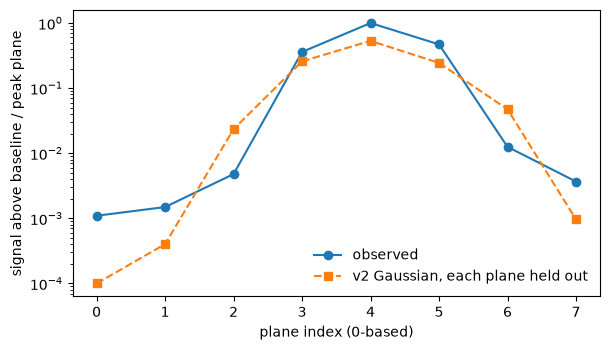

In [8]:
excess = np.array([(cube[:, :, k, :].sum((0, 1)) - p_all.base_ob).sum() for k in range(n_ob)])
rel = excess / excess.max()
print("ROI-summed counts above baseline, relative to the peak plane, by plane (0..7):")
print("  observed :", " ".join(f"{v:8.4f}" for v in rel))
# what a per-pixel Gaussian fitted to the other planes would say about each plane (the v2 model, held-out fold by fold)
pred_rel = []
for k in range(n_ob):
    tr = [j for j in range(n_ob) if j != k]
    m = d["fold_masks"][k][rc[:, 0], rc[:, 1]]
    pk = fm.fit_separable_params(cube, mu_g, chi_g, ob_g, tr)
    Ak, bk = fm.amplitude_and_baseline(pk)
    pred_rel.append(fm.predict_plane(pk, Ak, bk, ob_g[k]).sum((0, 1)).sum() - (bk * n_mu * n_chi).sum())
pred_rel = np.array(pred_rel) / excess.max()
print("  v2 Gaussian, held out:", " ".join(f"{v:8.4f}" for v in pred_rel))
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.semilogy(range(n_ob), np.clip(rel, 1e-4, None), "o-", label="observed")
ax.semilogy(range(n_ob), np.clip(pred_rel, 1e-4, None), "s--", label="v2 Gaussian, each plane held out")
ax.set_xlabel("plane index (0-based)"); ax.set_ylabel("signal above baseline / peak plane"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

The observed signal falls by about two orders of magnitude between neighbouring planes, so the per-pixel Gaussian over-predicts the planes
two steps off the peak and under-predicts the peak itself. The v3 fix keeps the mu and chi model and replaces only the obpitch factor: a
**global flat-top profile** (width and edge softness chosen on the training planes by a nested leave-one-training-plane-out search), with each pixel's
centre and amplitude **fitted** to it instead of taken from the centre of mass of 1.85 points per FWHM. Try it on this ROI. This ROI is the one the
fix was diagnosed on, so the numbers below are illustrations, not evidence; the evidence is the full-grain run that follows.

In [9]:
import midas_dfxm.forward_profile as fp
masks_all = {k: d["fold_masks"][k][rc[:, 0], rc[:, 1]] for k in range(n_ob)}
v3 = fp.leave_one_plane_out_profile(cube, mu_g, chi_g, ob_g, list(range(n_ob)), masks_all, nested_sub=P, keep=True)
v2_all = fm.leave_one_plane_out(cube, mu_g, chi_g, ob_g, list(range(n_ob)), masks_all)
print("held-out plane:", " ".join(f"{n:>8}" for n in d["planes"]))
print("v2 Gaussian   :", " ".join(f"{v2_all[k]['full']['r2']:8.2f}" for k in range(n_ob)))
print("v3 flat-top   :", " ".join(f"{v3[k]['r2']:8.2f}" for k in range(n_ob)))
print("profile chosen per fold (w, s in motor steps):", sorted({(v3[k]['w'], v3[k]['s']) for k in v3}))

held-out plane:      1.1      2.1      3.1      4.1      5.1      6.1      7.1      8.1
v2 Gaussian   :    -0.00    -0.01    -5.78     0.66     0.64     0.55   -18.19    -0.03
v3 flat-top   :    -0.00    -0.00    -0.56     0.77     0.86     0.81    -0.98    -0.00
profile chosen per fold (w, s in motor steps): [(1.6, 0.5)]


### B5. The flank fix on the whole grain

**The registered v3 run** (`examples/id03_forward_loo/PREREGISTER_v3.md`, `run_forward_loo_v3.py`, `results_v3.json`), on
683,234 pixels the design never saw. Held-out R², fold (0-based) / plane:

| fold / plane | v2 Gaussian obpitch | v3 flat-top obpitch |
|---|---|---|
| 0 / 1.1 | -0.063 | -0.002 |
| 1 / 2.1 | -6.617 | -0.308 |
| 2 / 3.1 | 0.067 | 0.426 |
| 3 / 4.1 (primary) | 0.501 | 0.674 |
| 4 / 5.1 (primary) | 0.573 | 0.705 |
| 5 / 6.1 (primary) | 0.492 | 0.682 |
| 6 / 7.1 | -11.171 | -0.131 |
| 7 / 8.1 | -0.125 | -0.003 |
| **pooled, primary planes** | **0.547** | **0.695** |

The profile chosen by the nested search was `w` = 1.6 steps, `s` = 0.5 steps in every fold. The block-shuffle
null scores -0.748 to -0.454 against observed 0.692 to 0.746
(p = 0.0099, the floor of 100 permutations). A matched synthetic world scores 0.977 through this pipeline against an oracle 0.999.

**Verdict of record: REFUTED, by the registered rule as written, and the reason is mine.** The registration named the "flank" folds from the
diagnosis ROI (folds 2 and 6). On the full grain the v2 failures are folds **1 and 6** (planes 2.1 and 7.1). One of the three refuting clauses
(fold 2 must gain 2 R² units over a v2 score that was already fine) is an artefact of that mis-indexing. Read with the right folds, which is a
post hoc reading and not a verdict: v3 gains 6.3 and 11.0 R² units on those two planes and 0.149 on the primary planes with no loss,
**but both flank planes are still slightly below zero** (-0.308 and -0.131). The flank failure is reduced by one to two orders of
magnitude, not removed. The v3 code lives in `midas_dfxm.forward_profile`; v3 is provisional until it has been through `/verify`.

## C. The package's physical forward model

Same maps, different machinery. `thin_slab_from_maps` builds one voxel per pixel whose deformation gradient is the
local lattice rotation (from the tilt maps) times an isotropic stretch (from the d-spacing map). Then, for every
(mu, chi, obpitch) setting, the package's own pieces do the physics: `GoniometerSetting` rotates the sample, the
accepted scattering vector at that `obpitch` is the Bragg `Q` of the beam deflected by 2 theta, and
`ResolutionFunction` weighs how far each voxel's `Q` sits from it, with anisotropic rock, roll and longitudinal widths.

Two honest choices to know about:

* **One width for the whole grain.** A voxel here has no intrinsic mosaic: it diffracts when its lattice meets the
  acceptance. The resolution widths are set so the *rendered* marginal widths equal the grain-median *measured* ones,
  which already contain the intrinsic part. At this sampling the two cannot be separated.
* **The detector projection is the identity** (one voxel per pixel). The row foreshortening is a display scale.

In [10]:
train = [j for j in range(n_ob) if j != k0]
mu_ref, chi_ref = float(np.median(p0.mu0[m0])), float(np.median(p0.chi0[m0]))
ob_ref0 = float(np.median(p0.ob0[m0])); th0 = np.deg2rad(ob_ref0) / 2
slab = ts.thin_slab_from_maps(p0.mu0 - mu_ref, p0.chi0 - chi_ref, -(np.deg2rad(p0.ob0 - ob_ref0) / 2) / np.tan(th0),
                              two_theta0_deg=ob_ref0, wavelength_A=LAM, mu_ref_deg=mu_ref, chi_ref_deg=chi_ref)
target = [np.median(p0.smu[m0]), np.median(p0.schi[m0]), np.median(p0.sob[m0])]
sig, achieved = ts.match_marginal_widths(slab, mu_g, chi_g, ob_g, target)
print("measured grain-median marginal sigmas (deg):", np.round(target, 4))
print("resolution widths put in (deg):             ", np.round(sig, 4), "  (the mu input is smaller: obpitch couples into the rock direction)")
print("rendered marginal sigmas (deg):             ", np.round(achieved, 4))
Wt = ts.render_weights(slab, mu_g, chi_g, ob_g, sigma_mu_deg=sig[0], sigma_chi_deg=sig[1], sigma_ob_deg=sig[2])
print("rendered cube", Wt.shape, "(unit-peak weights)")

measured grain-median marginal sigmas (deg): [0.02   0.0534 0.0236]
resolution widths put in (deg):              [0.0169 0.0534 0.024 ]   (the mu input is smaller: obpitch couples into the rock direction)
rendered marginal sigmas (deg):              [0.0202 0.0534 0.0235]


rendered cube (25, 26, 8, 11776) (unit-peak weights)


**Sign chain check.** The slab's rotation signs are fixed algebraically (a voxel diffracts at the setting that undoes
its lattice rotation; ID03 `mu` turns about -y, `chi` about +x). The check that this code does what it says: render,
take the moments the inversion takes, and the input maps must come back. This is a **code-consistency** check, not a
measurement of the beamline's motor signs.

In [11]:
cm, cc, co = ts.recovered_centres(Wt, mu_g, chi_g, ob_g)
rms = lambda a, b: 1e3 * np.sqrt(np.mean((a - b)[m0] ** 2))
print(f"rendered centres vs the maps they were built from (RMS, mdeg): mu {rms(cm, p0.mu0):.2f}, chi {rms(cc, p0.chi0):.3f}, "
      f"obpitch {rms(co, p0.ob0):.2f}   (a mu step is 40 mdeg)")

rendered centres vs the maps they were built from (RMS, mdeg): mu 2.13, chi 0.004, obpitch 0.35   (a mu step is 40 mdeg)


held-out plane 5.1:  physical forward R2 0.666   |   empirical full 0.635, uniform 0.358, abl_widths 0.621


physical forward vs the empirical model with one width for the grain: correlation 0.991


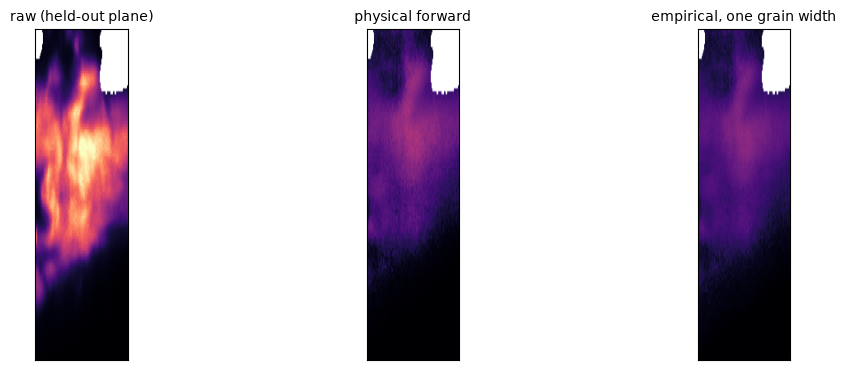

In [12]:
A = ts.fit_amplitudes(Wt, p0.mob_train, p0.base_ob, train)           # amplitude from the 7 training planes only
b = p0.base_ob / (n_mu * n_chi)
pred_phys = b[None, None] + A[None, None] * Wt[:, :, k0, :]
obs0 = cube[:, :, k0, :].astype(float)
sse_p = ((obs0 - pred_phys) ** 2).sum((0, 1)); sst_p = ((obs0 - obs0.mean((0, 1), keepdims=True)) ** 2).sum((0, 1))
print(f"held-out plane {d['planes'][k0]}:  physical forward R2 {fm.pooled_r2(sse_p, sst_p, m0):.3f}   |   "
      f"empirical full {res[k0]['full']['r2']:.3f}, uniform {res[k0]['uniform']['r2']:.3f}, abl_widths {res[k0]['abl_widths']['r2']:.3f}")
q_u = fm.ablate_params(p0, m0, ["smu", "schi", "sob"]); A2, b2 = fm.amplitude_and_baseline(q_u)
pe = fm.predict_plane(q_u, A2, b2, ob_g[k0])
c = np.corrcoef((pe - pe.mean((0, 1))).ravel(), (pred_phys - pred_phys.mean((0, 1))).ravel())[0, 1]
print(f"physical forward vs the empirical model with one width for the grain: correlation {c:.3f}")
i, j = i_pk, j_pk
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
vmax = np.nanpercentile(img(cube[i, j, k0, :]), 99.5)
for a, v, t in zip(ax, [cube[i, j, k0, :], pred_phys[i, j], pe[i, j]], ["raw (held-out plane)", "physical forward", "empirical, one grain width"]):
    a.imshow(img(v), cmap="magma", vmin=0, vmax=vmax, aspect=stretch); a.set_title(t, fontsize=10); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

The physical forward and the empirical model with one grain width are the same model written two ways, and they
agree closely; what separates them is the small coupling between obpitch and the rock direction that the package's
vector geometry carries and the separable Gaussian does not.

### C2. The same forward with a flat-top longitudinal acceptance

Section B4 showed that a Gaussian in obpitch is the wrong shape and B5 that a flat top fixes most of it. The physical forward had the same weakness because
`ResolutionFunction` only had a Gaussian longitudinal acceptance. It now has an optional `par_flat = (width, softness)`: an erf-edged box in the longitudinal
direction (default `None`, behaviour unchanged). `thin_slab_from_maps(..., )` plus `resolution_for_plane(..., flat_top_ob_deg=(width, softness))` use it.

To make the physical model the v3 model, build the slab from the **fitted** obpitch centres of v3 (not the centre of mass) and take the global `(w, s)` the nested
search chose on the training planes. Below: the Gaussian-acceptance version and the flat-top version, held-out, on one primary plane and the two flank planes of this ROI.

In [13]:
step = float(np.median(np.diff(ob_g)))
def physical_prediction(fold, flat_top):
    r = v3[fold]; p = r["_params"]; fit = r["_fit"]; m = masks_all[fold]; tr = [j for j in range(n_ob) if j != fold]
    ob_c = ob_g[0] + fit.c * step                                    # v3's fitted obpitch centres (deg)
    ob_ref = float(np.median(ob_c[m])); th = np.deg2rad(ob_ref) / 2
    mu_r, chi_r = float(np.median(p.mu0[m])), float(np.median(p.chi0[m]))
    sl = ts.thin_slab_from_maps(p.mu0 - mu_r, p.chi0 - chi_r, -(np.deg2rad(ob_c - ob_ref) / 2) / np.tan(th),
                                two_theta0_deg=ob_ref, wavelength_A=LAM, mu_ref_deg=mu_r, chi_ref_deg=chi_r)
    tg = [float(np.median(p.smu[m])), float(np.median(p.schi[m])), float(np.median(p.sob[m]))]
    if flat_top:
        ft = (fit.w * step, fit.s * step)                           # global width and edge softness, degrees of obpitch
        sg, _ = ts.match_marginal_widths(sl, mu_g, chi_g, ob_g, tg, flat_top_ob_deg=ft)
        Wk = ts.render_weights(sl, mu_g, chi_g, ob_g, sigma_mu_deg=sg[0], sigma_chi_deg=sg[1], flat_top_ob_deg=ft)
    else:
        sg, _ = ts.match_marginal_widths(sl, mu_g, chi_g, ob_g, tg)
        Wk = ts.render_weights(sl, mu_g, chi_g, ob_g, sigma_mu_deg=sg[0], sigma_chi_deg=sg[1], sigma_ob_deg=sg[2])
    A_ = ts.fit_amplitudes(Wk, p.mob_train, p.base_ob, tr)
    pr = (p.base_ob / (n_mu * n_chi))[None, None] + A_[None, None] * Wk[:, :, fold, :]
    ob_ = cube[:, :, fold, :].astype(float)
    sse_ = ((ob_ - pr) ** 2).sum((0, 1)); sst_ = ((ob_ - ob_.mean((0, 1), keepdims=True)) ** 2).sum((0, 1))
    return fm.pooled_r2(sse_, sst_, m)

rows = [(k, v3[k]["r2"], physical_prediction(k, True), physical_prediction(k, False)) for k in (k0, 1, 6)]
print(f"{'held-out plane':>16} {'v3 empirical':>13} {'physical, flat-top':>19} {'physical, Gaussian':>19}")
for k, a_, b_, c_ in rows:
    print(f"{d['planes'][k]:>16} {a_:13.3f} {b_:19.3f} {c_:19.3f}")

  held-out plane  v3 empirical  physical, flat-top  physical, Gaussian
             5.1         0.863               0.848               0.686
             2.1        -0.002              -0.002              -0.002
             7.1        -0.983              -0.638              -5.441


**Was the flat-top physical forward registered to equal v3? Registered verdict: NOT CONFIRMED** (`PREREGISTER_v3.md` section 14, `equiv_results.json`). Two 112 x 112 px ROIs, all 8 folds:

| ROI | v3 pooled R² (primary) | physical flat-top | lowest per-pixel correlation with v3 on a primary fold | Gaussian acceptance clearly worse on a flank fold |
|---|---|---|---|---|
| ROI-A (this one) | 0.845 | 0.834 | 0.92 | yes |
| ROI-B (never seen before) | 0.746 | 0.730 | 0.94 | yes |

The pooled primary scores agree within 0.02 on both ROIs, and swapping the Gaussian acceptance back in costs 4 to 5 R² units on the flank folds, so the flat top is
what matters. But the registration also required every single fold to agree within 0.10 and the per-pixel predictions to correlate at 0.98 or better, and neither
holds (correlations 0.81 to 0.98; single folds differ by up to 0.36 in either direction). The physical forward carries a coupling between obpitch and the rock
direction that the separable empirical model does not, so a difference is expected, and this check does not say which is nearer the truth. **v3's full-grain scores do
not transfer to the physical forward.**



**The physical forward on the whole grain** (`PREREGISTER_v4.md`, `run_physical_full.py`, `results_v4.json`; same pixels as v3), held-out R², fold / plane:

| fold / plane | v2 Gaussian obpitch | v3 flat-top empirical | physical, Gaussian acceptance | physical, flat-top acceptance |
|---|---|---|---|---|
| 0 / 1.1 | -0.063 | -0.002 | -0.007 | -0.002 |
| 1 / 2.1 | -6.617 | -0.308 | -3.250 | -0.658 |
| 2 / 3.1 | 0.067 | 0.426 | -0.255 | -0.024 |
| 3 / 4.1 (primary) | 0.501 | 0.674 | 0.548 | 0.535 |
| 4 / 5.1 (primary) | 0.573 | 0.705 | 0.657 | 0.660 |
| 5 / 6.1 (primary) | 0.492 | 0.682 | 0.568 | 0.595 |
| 6 / 7.1 | -11.171 | -0.131 | -5.869 | -0.336 |
| 7 / 8.1 | -0.125 | -0.003 | -0.025 | -0.003 |
| **primary pooled** | **0.547** | **0.695** | **0.621** | **0.624** |

**Registered verdict: INCONCLUSIVE.** Six of seven criteria held (no loss against v2, flank folds above -1 and far above v2, far folds at zero, block null, Gaussian control, matched
synthetic). The one that did not is agreement with v3 at the pooled level: 0.624 against 0.695, a gap of 0.071 for a tolerance of 0.05.

What to take from it: the flat-top acceptance does what it was added for (flank folds -3.25 and -5.87 with the Gaussian, -0.66 and -0.34 with the flat top; v2 had
-6.6 and -11.2), but on the primary planes it makes almost no difference (0.621 against 0.624), so most of the physical forward's gain over v2 comes from v3's fitted
obpitch centres. The physical forward is below v3, and both flank folds are still below zero. Why it loses to v3 was not diagnosed.



**v5: why was the physical forward below v3?** Three candidates were tested on the ROIs excluded from scoring (`PREREGISTER_v5.md`, decision rule fixed first): the obpitch-to-rock coupling of the accepted
vector (which the package's geometry has and the separable model lacks), one grain-wide rock/roll width in the slab where v3 has per-pixel widths, and the free per-pixel amplitude. Coupling and per-voxel widths each closed
roughly 45 % of the gap there and were carried; the amplitude is about half of the gap but is a diagnostic, not a model change. Whole-grain run with the coupling off and per-voxel widths, held-out R²:

| fold / plane | v3 empirical flat-top | v4 physical (coupled, grain widths) | v5 physical (no coupling, per-voxel widths) |
|---|---|---|---|
| 0 / 1.1 | -0.002 | -0.002 | -0.002 |
| 1 / 2.1 | -0.308 | -0.658 | -0.339 |
| 2 / 3.1 | 0.426 | -0.024 | 0.419 |
| 3 / 4.1 (primary) | 0.674 | 0.535 | 0.677 |
| 4 / 5.1 (primary) | 0.705 | 0.660 | 0.707 |
| 5 / 6.1 (primary) | 0.682 | 0.595 | 0.691 |
| 6 / 7.1 | -0.131 | -0.336 | -0.197 |
| 7 / 8.1 | -0.003 | -0.003 | -0.003 |
| **primary pooled** | **0.695** | **0.624** | **0.699** |

**Registered verdict: CONFIRMED**, all seven criteria (within 0.05 of v3, no loss against v2 and v4, flank folds -0.34 and -0.20, block null, Gaussian-acceptance control, matched synthetic).
Read it for what it is: the per-pixel correlation with v3 is 0.9987, so with the coupling off and per-voxel widths the physical forward **is** v3 expressed in the package's geometry. The finding is that the coupled
geometry, as parametrised here, scored about 0.07 lower on this scan, and that this run does not say whether the instrument decouples better than the geometry or the coupling is mis-specified. `couple=False` is a diagnostic switch, not a statement that the coupling is absent.
The flank folds are still below zero in point estimate (fold 6 is not statistically distinguishable from zero).

**`/verify` of this claim: PROVISIONAL** (four refuters; reproduction and physics SURVIVE, statistics and artifact UNCERTAIN). What they narrow, so you read the number correctly:
* quote the primary R² as **about 0.70 ± 0.05** (block bootstrap, at most about 60 independent blocks, one grain, one scan; plane 4 carries 65 % of the pooled score);
* physical minus empirical flat-top is **+0.003**, about 1 % of the squared error: they are equal, not better or worse. Physical beats the Gaussian-obpitch model by +0.152, which is firm;
* an independent implementation from the written model reproduces it (0.6995 and 0.6997 against 0.6986), and flipping the sign of a tilt collapses the score, so the geometry does carry content; the d-spacing channel contributes little;
* **the obpitch-rock coupling strength is not pinned by the data**: one ROI prefers it on, the other off, so the v4 finding that the coupled geometry scored lower may be ROI dependent;
* the plain average of the two planes adjacent to the held-out one, with no model, scores 0.66, and the difference to 0.70 is within the interval; the per-frame pedestal is a signal proxy, and the target is pedestal-subtracted frames, not raw ones.



**v6: the two remaining levers, the coupling strength and the amplitude** (`PREREGISTER_v6.md`).
*Coupling, measured without a model on the whole grain:* the slope of each pixel's mu centroid against obpitch, pooled over 763,188 pixels, is **0.0725** deg/deg
(block-bootstrap [0.042, 0.107]; a synthetic cube with full coupling gives 0.473 through the same estimator, a shuffle gives 0), i.e. an effective strength of 0.15
against a geometry that would give 1. **`/verify`: PROVISIONAL.** The slope reproduces, but it is not demonstrated to be coupling: the same estimator on the **chi** centroid, where the geometry predicts none, gives -0.06; the plane order, the obpitch and the acquisition time are one variable, so a drift cannot be
separated; the value is spatially structured (about 4x between regions) and 58 % of the numerator comes from the top and bottom 64 rows; and the honest interval is about [0.015, 0.13], wider than the bootstrap's. Read it as an effective plane-dependent mu shift of 1-3 mdeg.
*Amplitude:* with oracle amplitudes (each pixel's amplitude refitted on the held-out plane) the gain over v3 is 0.087, with an oracle centre 0.083, with one scalar per plane 0.036, with a global profile 0.031 (two excluded ROIs): the amplitude and the centre are the same held-out error seen two ways.
*A registered v6* (coupling strength 0.153 plus a spatially pooled amplitude chosen by the training planes) scores **0.6994** against v5's 0.699: **no improvement** (INCONCLUSIVE). The training planes reject any smoothing of the amplitude (L = 1 in every fold), and a coupling of 0.153 is worth +0.0008.
The remaining 0.07-0.09 is amplitude/centre error of the held-out plane that seven training planes cannot supply.


## D. What this does and does not tell you

**It tells you** whether the per-pixel centres and widths in the maps are a sufficient summary of the stack: for planes
the maps never saw, on the grain, how much of the frame-to-frame variation they regenerate, against baselines that can
lose, and against the noiseless ceiling of the model class at this sampling.

**It does not tell you:**

* **Physical accuracy.** The maps came from this sample, optic and background. A held-out plane removes the direct leak
  only. (`README.md` rule 5: a round trip is a software-consistency check.)
* **Strain.** One reflection gives `delta d / d`, and more than 90 % of the obpitch width is objective acceptance
  (`ENVELOPE.md` section 6). A composition change moves `d` exactly like strain does.
* **Depth or 3-D structure.** One layer, one reflection, sample never translated: the maps are a 2-D projection.
* **Twins, two orientations in one pixel.** A single Gaussian per pixel cannot represent them. They are the main
  structural reason a pixel's R² goes negative, and chi (3.4 points per FWHM) is the axis that could resolve them;
  mu (about 1) cannot.
* **Absolute orientation.** The tilts are relative to the grain median; the labDCT frame transform is not established.
* **That the maps beat the data they came from.** An independent refuter found that the plain mean of the two planes adjacent to a held-out plane scores *higher*
  (R² 0.66) than the per-pixel model of section B (0.548): the held-out planes sit between training planes 0.02 deg apart, so this is interpolation, and
  "regenerates the frames" should be read as "summarises them at about this fidelity", not as compression without loss.
* **The physical forward matches the empirical v3 only with the obpitch-rock coupling switched off and per-voxel widths (v5), at which point it is v3 in package geometry.** With the package's coupled geometry it scored about 0.07 below v3
  (v4), and with a Gaussian longitudinal acceptance it fails the flank planes (B4). Whether the coupling is real physics or a mis-specified rate on this instrument is not decided: a model-free measurement gives an effective mu-obpitch slope that cannot be attributed to coupling (v6, `/verify` PROVISIONAL).